<a href="https://colab.research.google.com/github/DezT-217/data-art-notebooks/blob/main/animals_cnn_embeddings_pacmap.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Visualizing CNN Embeddings with PaCMAP — Animals Dataset

In [1]:
!pip install torch torchvision pacmap matplotlib scikit-learn kaggle tqdm pillow

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 19.5/19.5 MB 33.2 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [pacmap]


In [2]:
import os
import numpy as np
from PIL import Image
from tqdm import tqdm

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, TensorDataset

import matplotlib.pyplot as plt
import pacmap
from sklearn.model_selection import train_test_split

torch.manual_seed(0)  # for reproducibility
np.random.seed(0)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

Using device: cuda


In [3]:
# ============ DATASET CONFIG: edit this cell to switch datasets ============

# --- Download ---
KAGGLE_SLUG = "iamsouravbanerjee/animal-image-dataset-90-different-animals"  # owner/dataset-name from the Kaggle URL
ZIP_NAME    = KAGGLE_SLUG.split("/")[-1] + ".zip"                            # Kaggle names the zip after the dataset
DATA_ROOT   = "animals_data"                                                 # folder to extract into

# --- Finding the class folders ---
MIN_CLASSES = 50      # find_class_root accepts a folder with at least this many subfolders
                      # (set to roughly half your real class count, or 2 for tiny datasets)

# --- Plot 2 ---
HIGHLIGHT   = ["cat", "dog", "lion", "tiger", "elephant",
               "dolphin", "eagle", "butterfly", "horse", "penguin"]  # class names to color; max 10 with tab10
DATASET_LABEL = "animals"   # used in plot titles

# --- Optional: values you may want to tune per dataset ---
IMG_SIZE      = 224   # ResNet's usual input size; keep unless you have a reason
TEST_SIZE     = 0.25
BATCH_SIZE    = 64
EMBEDDING_DIM = 256
LEARNING_RATE = 5e-4
NUM_EPOCHS    = 15
SEED          = 0     # random_state for the split and PaCMAP

## Download the dataset from Kaggle

In [4]:
try:
    from google.colab import userdata
    os.environ["KAGGLE_API_TOKEN"] = userdata.get("KAGGLE_API_TOKEN")
except Exception:
    pass  # not in Colab, or no secret set — fall back to an env var / kaggle.json

In [5]:
if not os.path.isdir(DATA_ROOT):
    !kaggle datasets download -d {KAGGLE_SLUG}
    !unzip -q {ZIP_NAME} -d {DATA_ROOT}
else:
    print(f"{DATA_ROOT} already exists — skipping download")

Dataset URL: https://www.kaggle.com/datasets/iamsouravbanerjee/animal-image-dataset-90-different-animals
License(s): other
100% 656M/656M [00:09<00:00, 75.2MB/s]



In [6]:
def find_class_root(root):
  ## dirpath -> path of current folder
  ## dirnames -> list of names of subfolders inside
  ## filenames -> list of names of files inside
    for dirpath, dirnames, filenames in os.walk(root): ## visiting root folder and then nested folders
        if len(dirnames) >= MIN_CLASSES and not filenames:
            return dirpath

    raise FileNotFoundError(f"Couldn't find the class folders under {root}")

IMAGE_DIR = find_class_root(DATA_ROOT)

print("Image folder:", IMAGE_DIR)

Image folder: animals_data/animals/animals


## 1. Load the images

In [7]:
IMG_SIZE = 224 ## 244x244 pixels is common for ResNet CNNs
IMAGE_EXTS = (".jpg", ".jpeg", ".png", ".bmp")

## os.listeddir(IMAGE_DIR) -> list of everything in main image folder
## os.path.join(IMAGE_DIR, d) -> builds the full path
## os.path.isdir(...) -> true if path is folder
## sorted(...) -> alphabetical order
## results in a list of folder names, one per class
class_names = sorted(d for d in os.listdir(IMAGE_DIR) if os.path.isdir(os.path.join(IMAGE_DIR, d)))
## maps each class name to a number
## enumerate(...) creates (index, item) pairs
class_to_idx = {name: i for i, name in enumerate(class_names)}

num_classes = len(class_names)

print(f"{num_classes} classes, e.g. {class_names[:5]}")

images, labels, skipped = [], [], 0

## looping over every class folder name
## tqdm(...) creates a progress bar, the desc being the label
for name in tqdm(class_names, desc="Loading classes"):
    ## creating full path to this class's folder
    class_dir = os.path.join(IMAGE_DIR, name)

    for fname in sorted(os.listdir(class_dir)):
        if not fname.lower().endswith(IMAGE_EXTS):
            continue

        try:
            with Image.open(os.path.join(class_dir, fname)) as img:
                ## converting to the same image size for all and forcing 3 color channels
                img = img.convert("RGB").resize((IMG_SIZE, IMG_SIZE))

                images.append(np.asarray(img, dtype=np.uint8))
        except Exception:
            skipped += 1
            continue

        labels.append(class_to_idx[name])

print(f"Loaded {len(images)} images, skipped {skipped} unreadable ones")

90 classes, e.g. ['antelope', 'badger', 'bat', 'bear', 'bee']


Loading classes: 100%|██████████| 90/90 [01:13<00:00,  1.22it/s]

Loaded 5400 images, skipped 0 unreadable ones


Train: 4050 images, Test: 1350 images
Tensor shape: (4050, 3, 224, 224) (N, channels, height, width)


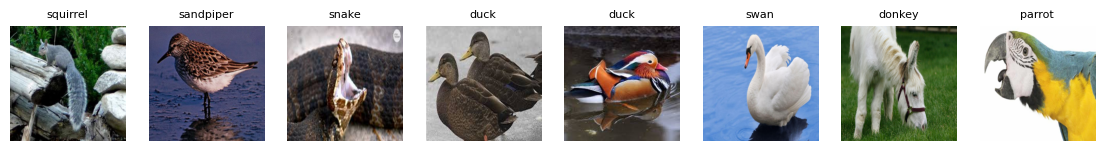

In [8]:
## permute(...) just alters the order of the stored dims (getting channels to be second)
## stack(...) turns the list of arrays into one "stacked" array
X = torch.tensor(np.stack(images)).permute(0, 3, 1, 2)
y = torch.tensor(labels, dtype=torch.long)
del images

X_train, X_test, y_train, y_test = train_test_split(
    X, y,                     ## data and labels
    test_size=TEST_SIZE,      ## 25% of data to testing, other 75% to training
    random_state=SEED,
    stratify=y                ## keeps class proportions same in both sets, so every class is in both
)

## TensorDataset(X_train, y_train) -> pairs each image with its label
## DataLoader(...) -> hands the data to the model in small batches
## batch_size=64 -> 64 images per batch
## shuffle=True -> reshuffles the order every epoch so model doesn't memorize
train_loader = DataLoader(TensorDataset(X_train, y_train), batch_size=BATCH_SIZE, shuffle=True)

print(f"Train: {len(X_train)} images, Test: {len(X_test)} images")
print("Tensor shape:", tuple(X_train.shape), "(N, channels, height, width)")

fig, axes = plt.subplots(1, 8, figsize=(14, 2.2))

for ax, img, label in zip(axes, X_train, y_train):
    ax.imshow(img.permute(1, 2, 0).numpy())
    ax.set_title(class_names[label.item()], fontsize=8)
    ax.axis("off")

plt.show()

## 2. Define a simple CNN

```
image → conv1 → pool → conv2 → pool → adaptive pool → flatten → fc_features → classifier
```

In [9]:
MEAN = torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1).to(device)
STD  = torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1).to(device)

def prep(xb):
    """uint8 batch on any device -> normalized float batch on `device`."""
    ## xb.to(device) -> moves batch to model's device
    ## .float() -> converts uint8 to 32-bit decimals
    ## / 255.0 -> scales pixels values to 0-1
    ## - MEAN - > subtracts each channel's average, centering data around 0
    ## / STD -> divides by each channel's spread, so values mostly fall between about -2 and +2
    return (xb.to(device).float() / 255.0 - MEAN) / STD

In [31]:
from torchvision import models

class ResNetEmbedder(nn.Module):
    ## runs once model is created, building the layers
    ## embedding_dim=256 -> size of embedding; 256 numbers per image
    ## droprate=0.3 -> dropout rate; 30% of vals randomly zeroed during training
    ## num_classes=90 -> number of output classes
    def __init__(self, embedding_dim=256, droprate=0.3, num_classes=90):
        super().__init__()
        ## loads ResNet-101
        ## weights="IMAGENET1K_V1" -> downloading weights learned from ImageNet
        ## instead of starting with random ones
        self.base_model = models.resnet152(weights="IMAGENET1K_V1")

        ## looping over every learnable parameter (weights and biases) in ResNet
        for p in self.base_model.parameters():
            ## freezes parameter and stops gradient calculations for it
            ## keeps pretrained knowledge intact
            p.requires_grad = False

        ## reading ResNet's original last layer (.fc) of 512 numbers
        in_features = self.base_model.fc.in_features

        ## replaces the final classification layer of ResNet with nn.Identity,
        ## which is just unchanged input
        self.base_model.fc = nn.Identity()
        ## new fully connected layer: 512 inputs -> 256 outputs
        self.fc_features = nn.Linear(in_features, embedding_dim)
        ## dropout layer: randomly sets 30% of vals to zero during training to prevent overfitting
        self.dropout = nn.Dropout(droprate)
        ## final classification layer: 256 embedding vals -> 90 scores, one per class
        self.classifier = nn.Linear(embedding_dim, num_classes)

    ## a helper method producing just the embedding (essentially a compact numeric "fingerprint" of the image)
    def embed(self, x):
        ## runs images through frozen ResNet
        x = self.base_model(x)

        ## passes the 512 features through linear layer to get 256 numbers, then applys ReLU
        return F.relu(self.fc_features(x))

    def forward(self, x):
        ## image -> embedding -> dropout -> classifier -> 90 classes
        return self.classifier(self.dropout(self.embed(x)))

model = ResNetEmbedder(embedding_dim=EMBEDDING_DIM, num_classes=num_classes).to(device)

Downloading: "https://download.pytorch.org/models/resnet152-394f9c45.pth" to /root/.cache/torch/hub/checkpoints/resnet152-394f9c45.pth


100%|██████████| 230M/230M [00:05<00:00, 40.9MB/s]


## 3. Train the CNN

In [32]:
optimizer = torch.optim.Adam(
    [p for p in model.parameters() if p.requires_grad], lr=LEARNING_RATE
)

loss_fn = nn.CrossEntropyLoss()

for epoch in range(NUM_EPOCHS):
    ## puts model in training mode
    model.train()
    ## puts the ResNet backbone into eval mode to keep it fixed
    model.base_model.eval()
    total_loss = 0.0

    for images_b, labels_b in train_loader:
        images_b, labels_b = prep(images_b), labels_b.to(device)

        ## clears gradients from previous batch
        optimizer.zero_grad()
        ## computes loss
        loss = loss_fn(model(images_b), labels_b)
        ## computes gradient of the loss and determines which direction to nudge parameters
        loss.backward()
        ## updates weights using gradients
        optimizer.step()
        total_loss += loss.item() * len(images_b)

    print(f"Epoch {epoch + 1:2d}/{NUM_EPOCHS} — avg loss: {total_loss / len(X_train):.4f}")

Epoch  1/15 — avg loss: 3.4046
Epoch  2/15 — avg loss: 1.4177
Epoch  3/15 — avg loss: 0.7925
Epoch  4/15 — avg loss: 0.5591
Epoch  5/15 — avg loss: 0.4430
Epoch  6/15 — avg loss: 0.3674
Epoch  7/15 — avg loss: 0.3107
Epoch  8/15 — avg loss: 0.2715
Epoch  9/15 — avg loss: 0.2311
Epoch 10/15 — avg loss: 0.2068
Epoch 11/15 — avg loss: 0.1769
Epoch 12/15 — avg loss: 0.1673
Epoch 13/15 — avg loss: 0.1567
Epoch 14/15 — avg loss: 0.1365
Epoch 15/15 — avg loss: 0.1301


In [33]:
@torch.no_grad()
def run_in_batches(fn, X, batch_size=256):
    model.eval()
    ## loops over set of images in chunks:
    ## range(0, len(X), batch_size) -> stars indices 0, 256, 512, ...
    ## X[i:i + batch_size] -> slices out one chunck of images
    ## prep(...) -> normalizes the chunck and moves it to the device
    ## fn(...) -> runs the model on it
    ## .cpu() -> moves the result back to CPU memory
    outputs = [fn(prep(X[i:i + batch_size])).cpu() for i in range(0, len(X), batch_size)]

    return torch.cat(outputs)

test_preds = run_in_batches(model, X_test).argmax(dim=1)

accuracy = (test_preds == y_test).float().mean()

print(f"Test accuracy: {accuracy:.1%}  (random guessing would be {1 / num_classes:.1%})")

Test accuracy: 93.5%  (random guessing would be 1.1%)


## 4. Collect the final feature layer embeddings

In [34]:
embeddings = run_in_batches(model.embed, X_test).numpy()

print(f"Embeddings shape: {embeddings.shape}  (num images, embedding dimension)")

Embeddings shape: (1350, 256)  (num images, embedding dimension)


## 5. Project to 2D with PaCMAP and plot

In [35]:
reducer = pacmap.PaCMAP(n_components=2, random_state=SEED)
embeddings_2d = reducer.fit_transform(embeddings)

print(f"Projected shape: {embeddings_2d.shape}")

Projected shape: (1350, 2)


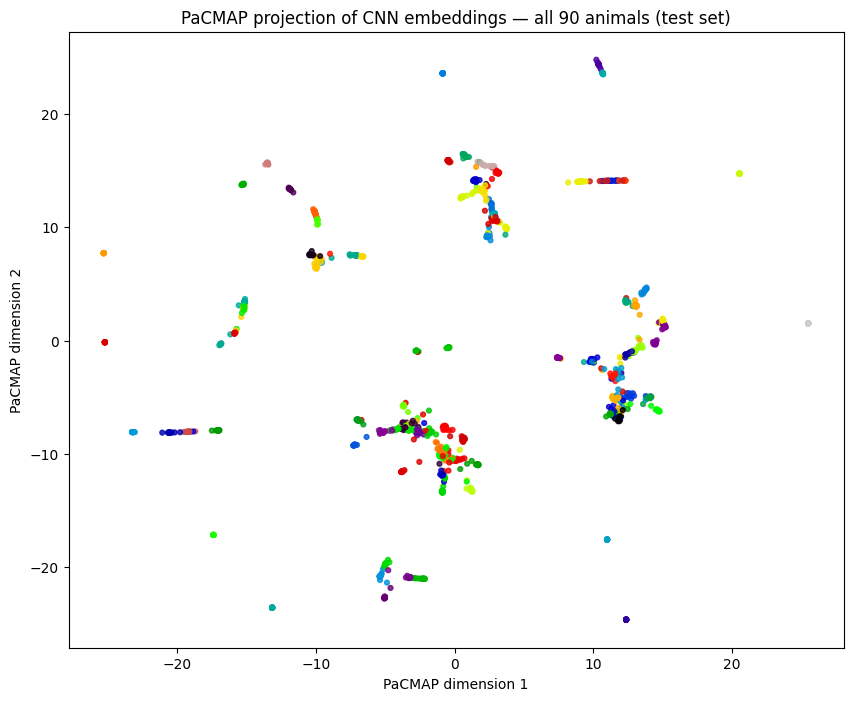

In [36]:
y_test_np = y_test.numpy()

plt.figure(figsize=(10, 8))

plt.scatter(
    embeddings_2d[:, 0],
    embeddings_2d[:, 1],
    c=y_test_np,
    cmap="nipy_spectral",
    s=12,
    alpha=0.8,
)

plt.title(f"PaCMAP projection of CNN embeddings — all {num_classes} {DATASET_LABEL} (test set)")
plt.xlabel("PaCMAP dimension 1")
plt.ylabel("PaCMAP dimension 2")
plt.show()

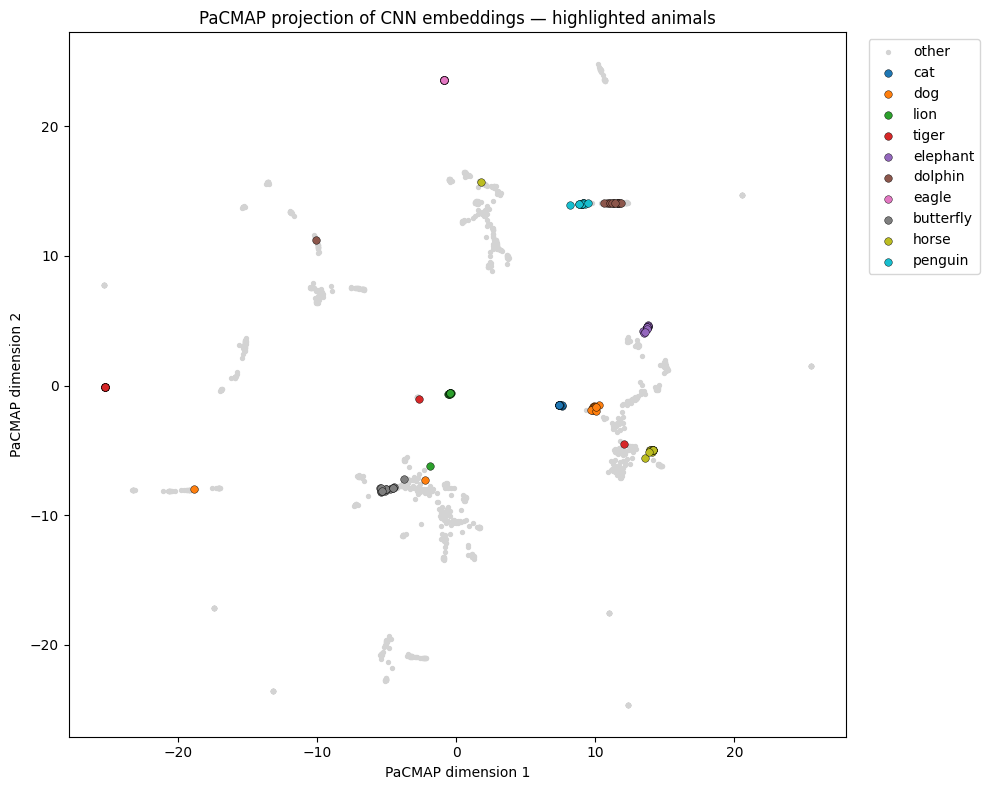

In [37]:
highlight = [c for c in HIGHLIGHT if c in class_to_idx]

plt.figure(figsize=(10, 8))

other = ~np.isin(y_test_np, [class_to_idx[c] for c in highlight])

plt.scatter(
    embeddings_2d[other, 0],
    embeddings_2d[other, 1],
    c="lightgray",
    s=8,
    label="other")

colors = plt.cm.tab10(np.linspace(0, 1, 10))

for color, name in zip(colors, highlight):
    mask = y_test_np == class_to_idx[name]
    plt.scatter(embeddings_2d[mask, 0], embeddings_2d[mask, 1], color=color, s=30, label=name, edgecolor="k", linewidth=0.3)

plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.title("PaCMAP projection of CNN embeddings — highlighted animals")
plt.xlabel("PaCMAP dimension 1")
plt.ylabel("PaCMAP dimension 2")
plt.tight_layout()
plt.show()